This groundbreaking dataset contains over 13 million pieces of evidence across 33 entity types, covering 1.6 million alerts and 1 million annotated incidents. The dataset represents alerts or incidents logged by the SIEM system.

In [13]:
import pandas as pd
import numpy as np

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Dataset path
file_path = '/content/drive/My Drive/datasets/GUIDE_Test.csv'

# Step 1: Load the dataset
try:
    df = pd.read_csv(file_path)
    print("Dataset successfully loaded!")
except FileNotFoundError:
    print("File not found. Please check the file path.")
    exit()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


<ipython-input-13-079182062737>:13: DtypeWarning: Columns (10,11) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path)


Dataset successfully loaded!


In [14]:
# Step 2: Basic exploration
print("\nDataset Shape:", df.shape)
print("\nFirst few rows of the dataset:")
print(df.head())



Dataset Shape: (4147992, 46)

First few rows of the dataset:
              Id  OrgId  IncidentId  AlertId                 Timestamp  \
0  1245540519230    657       11767    87199  2024-06-04T22:56:27.000Z   
1  1400159342154      3       91158   632273  2024-06-03T12:58:26.000Z   
2  1279900255923    145       32247   131719  2024-06-08T03:20:49.000Z   
3    60129547292    222       15294   917686  2024-06-12T12:07:31.000Z   
4   515396080539    363        7615     5944  2024-06-06T17:42:05.000Z   

   DetectorId  AlertTitle           Category                  MitreTechniques  \
0         524         563    LateralMovement      T1021;T1047;T1105;T1569.002   
1           2           2  CommandAndControl                              NaN   
2        2932       10807    LateralMovement  T1021;T1027.002;T1027.005;T1105   
3           0           0      InitialAccess                  T1078;T1078.004   
4          27          18          Discovery                  T1087;T1087.002   

    In

In [15]:
# Step 2: Basic exploration - Column names and data types
print("\nColumn Names and Data Types:")
for column in df.columns:
    print(f"Column: {column} - Type: {df[column].dtype}")

# Alternatively, use the pandas `dtypes` property
print("\nData Types Overview:")
print(df.dtypes)



Column Names and Data Types:
Column: Id - Type: int64
Column: OrgId - Type: int64
Column: IncidentId - Type: int64
Column: AlertId - Type: int64
Column: Timestamp - Type: object
Column: DetectorId - Type: int64
Column: AlertTitle - Type: int64
Column: Category - Type: object
Column: MitreTechniques - Type: object
Column: IncidentGrade - Type: object
Column: ActionGrouped - Type: object
Column: ActionGranular - Type: object
Column: EntityType - Type: object
Column: EvidenceRole - Type: object
Column: DeviceId - Type: int64
Column: Sha256 - Type: int64
Column: IpAddress - Type: int64
Column: Url - Type: int64
Column: AccountSid - Type: int64
Column: AccountUpn - Type: int64
Column: AccountObjectId - Type: int64
Column: AccountName - Type: int64
Column: DeviceName - Type: int64
Column: NetworkMessageId - Type: int64
Column: EmailClusterId - Type: float64
Column: RegistryKey - Type: int64
Column: RegistryValueName - Type: int64
Column: RegistryValueData - Type: int64
Column: ApplicationId

In [16]:
# Check unique values in the 'Category' column
print("Unique values in the 'Category' column:")
print(df['Category'].unique())

# Count occurrences of each value in the 'Category' column
print("\nValue counts in the 'Category' column:")
print(df['Category'].value_counts())


Unique values in the 'Category' column:
['LateralMovement' 'CommandAndControl' 'InitialAccess' 'Discovery'
 'SuspiciousActivity' 'Impact' 'CredentialAccess' 'Exfiltration'
 'UnwantedSoftware' 'DefenseEvasion' 'Malware' 'Execution' 'Persistence'
 'CredentialStealing' 'Collection' 'Ransomware' 'Exploit'
 'PrivilegeEscalation' 'WebExploit']

Value counts in the 'Category' column:
Category
InitialAccess          1952969
Exfiltration            615284
SuspiciousActivity      440093
CommandAndControl       357179
Impact                  307810
CredentialAccess        130196
Execution               115658
Malware                  71593
Discovery                63633
Persistence              29075
DefenseEvasion           21611
LateralMovement          19426
UnwantedSoftware          7496
Collection                6272
Ransomware                5605
Exploit                   1653
PrivilegeEscalation       1555
CredentialStealing         873
WebExploit                  11
Name: count, dtype: in

Level Categories

*   **InitialAccess** -> Indicates attempts to gain unauthorized access to a system or network, such as phishing or exploiting vulnerabilities.
*   **Exfiltration** - Refers to the unauthorized transfer of data out of a system
*   **SuspiciousActivity**- > Represents events flagged as suspicious but not definetively malicious
*   **CommandAndControl** - Refers to comunication between an infected host and the attacker´s server.
*   **Impact** - Actions that directly harm the system such as deleting files or encrypting data.
*   **CredentialAccess**- Atemps to steal user credentials
*   **Execution**- Refers to the execution of malicious code on a host system
*   **Malware**- Malicious software
*   **Discovery** - Activities aimed at understanding the environment such as scanning or enumeration.
*   **Persistence**- Attemps to maintain unauthorized access over time
*   **DefenseEvasion**- Techniques to avoid detection , such as disabling antivirus software.
*   **LateralMovement**- Moving accross systems within a network to expand access
*   **UnwantedSoftware**- Software that is not necessary malicious but undesirable
*   **Collection** - Gathering sensitive data for exfiltration .
*   **Ransomware** - Encrypting files and demanding payment for decryption .
*   **Exploit** - Use of vulnerabilities to gain control or execute malicious actions

*   **Priviledge escalation **-Gaining higher levels of accses or priviledges on a system
*   **CredentialStaling** - A specific form of credential access focused on stealing sensitive credentials.
*   **WebExploit** - Web-based exploitating ofen through vulnerable web applications.
















In [17]:
# Check unique values in the 'MitreTechniques' column
print("Unique values in the 'MitreTechniques' column:")
print(df['MitreTechniques'].unique())

# Count occurrences of each technique combination
print("\nValue counts in the 'MitreTechniques' column:")
print(df['MitreTechniques'].value_counts())

# Extract and count individual techniques
print("\nCounting individual techniques from the 'MitreTechniques' column:")
technique_counts = df['MitreTechniques'].dropna().str.split(';').explode().value_counts()
print(technique_counts)


Unique values in the 'MitreTechniques' column:
['T1021;T1047;T1105;T1569.002' nan 'T1021;T1027.002;T1027.005;T1105'
 'T1078;T1078.004' 'T1087;T1087.002' 'T1111;T1557' 'T1566'
 'T1007;T1016;T1018;T1049;T1087;T1135;T1574.007' 'T1568;T1008'
 'T1046;T1030;T1071;T1071.001' 'T1566.002' 'T1059.001;T1059.005;T1059.007'
 'T1071;T1048' 'T1133' 'T1003;T1012;T1552.002' 'T1559;T1106;T1059.005'
 'T1566.001' 'T1110;T1110.003;T1110.001' 'T1110;T1078' 'T1071;T1571'
 'T1046;T1071;T1210' 'T1078;T1098' 'T1078' 'T1059.003' 'T1110;T1110.003'
 'T1036.004;T1543.003;T1569.002;T1574.011'
 'T1027.002;T1027.005;T1059.003;T1105'
 'T1059;T1203;T1559;T1106;T1053;T1129;T1072;T1569;T1204;T1047;T1071;T1092;T1132;T1001;T1568;T1008;T1105;T1104;T1095;T1571;T1572;T1090;T1219;T1205;T1102;T1548;T1134;T1197;T1612;T1140;T1610;T1006;T1484;T1211;T1564;T1574;T1562;T1070;T1202;T1036;T1556;T1112;T1601;T1027;T1542;T1055;T1207;T1218;T1216;T1553;T1221;T1127;T1550;T1078;T1497;T1600;T1220;T1210;T1563;T1021;T1091'
 'T1110;T1110.001;T1110

**Most Frequent Techniques**
**T1078** (Valid Accounts):
Frequency: 659,606
Description: Use of stolen or valid credentials to gain unauthorized access.
Implication: Indicates attackers often use compromised accounts to bypass security controls.

**T1078.004** (Cloud Accounts):Frequency: 617,374
Description: A sub-technique of T1078 specific to cloud environments.
Implication: Highlights the prevalence of cloud account compromise in incidents.

**T1566.002 ** (Spearphishing Link):

Frequency: 360,219
Description: Spearphishing attacks with malicious links sent to targeted individuals.
Implication: Phishing remains one of the most effective techniques for initial access.

**T1566** (Phishing):Frequency: 277,038
Description: General phishing techniques, including email and SMS phishing.
Implication: A broader category encompassing various social engineering methods.

**T1133** (External Remote Services):Frequency: 119,289
Description: Exploitation of remote services (e.g., RDP, VPN) for unauthorized access.
Implication: Attackers commonly exploit insecure or misconfigured remote services.


In [18]:
print(df['IncidentGrade'].value_counts())
print(df['SuspicionLevel'].value_counts())



IncidentGrade
BenignPositive    1752940
TruePositive      1492354
FalsePositive      902698
Name: count, dtype: int64
SuspicionLevel
Suspicious      649454
Incriminated       381
Name: count, dtype: int64


**INCIDENT GRADE**

**BeningPositive** - These are alerts flagged by the SIEM as suppicous but later determined to be non-malicious or bening

**True Positive** - Alerts confirmed to represent actual threats or malicious activities

**False Positives-** Alerts flagged incorrectly as suspicious by the SIEM system

**SUSPICIOUS LEVEL**


**Suspcious** - these alerts are flagged with a moderate to high level of suspicioon

**Incriminated**- These are alerts where the SIEM has very hihgh confidence that the envent is malicious or directly tied to an attack.

In [19]:
category_techniques = df.groupby('Category')['MitreTechniques'].count()
print(category_techniques)


Category
Collection                3963
CommandAndControl        58117
CredentialAccess        111661
CredentialStealing         873
DefenseEvasion           14844
Discovery                57903
Execution                42732
Exfiltration             12046
Exploit                    218
Impact                    6495
InitialAccess          1449011
LateralMovement          15624
Malware                  28201
Persistence              27056
PrivilegeEscalation        912
Ransomware                 321
SuspiciousActivity       10438
UnwantedSoftware           462
WebExploit                  11
Name: MitreTechniques, dtype: int64


Top categories in TruePositive events:
Category
InitialAccess          1051798
SuspiciousActivity      161258
Impact                   85878
CommandAndControl        56052
CredentialAccess         55086
Exfiltration             32881
Execution                16250
Malware                  13180
Discovery                 7030
DefenseEvasion            4315
LateralMovement           3376
Collection                1781
Persistence               1216
UnwantedSoftware          1023
Ransomware                 884
Exploit                    299
PrivilegeEscalation         36
CredentialStealing           9
WebExploit                   2
Name: count, dtype: int64

Top MITRE techniques in TruePositive events:
MitreTechniques
T1078        472843
T1078.004    469551
T1566.002    128154
T1566         62737
T1110         51490
              ...  
T0890             2
T0853             2
T0859             1
T0816             1
T1552.004         1
Name: count, Length: 265, dtype: int64

Cross-analysis 

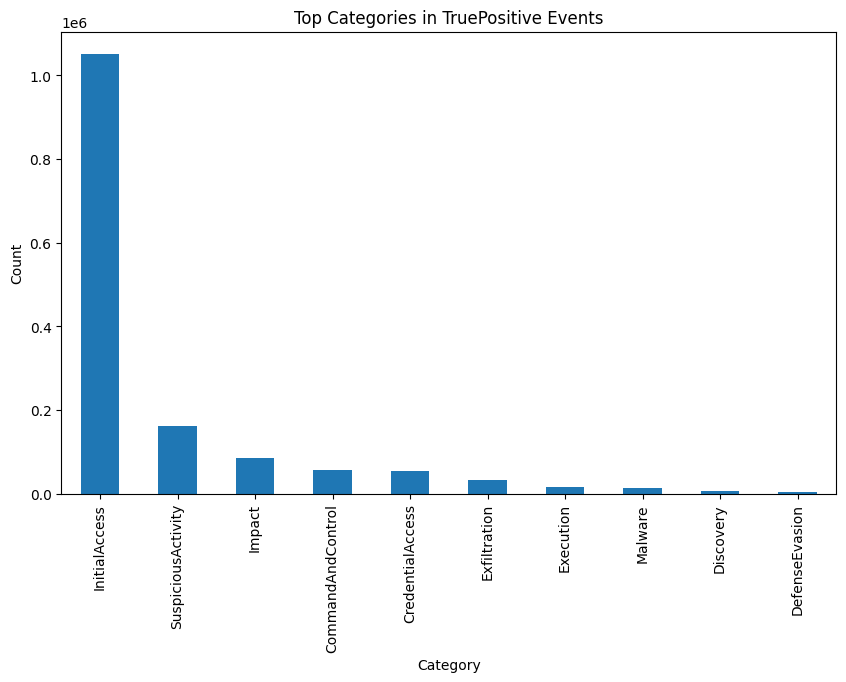

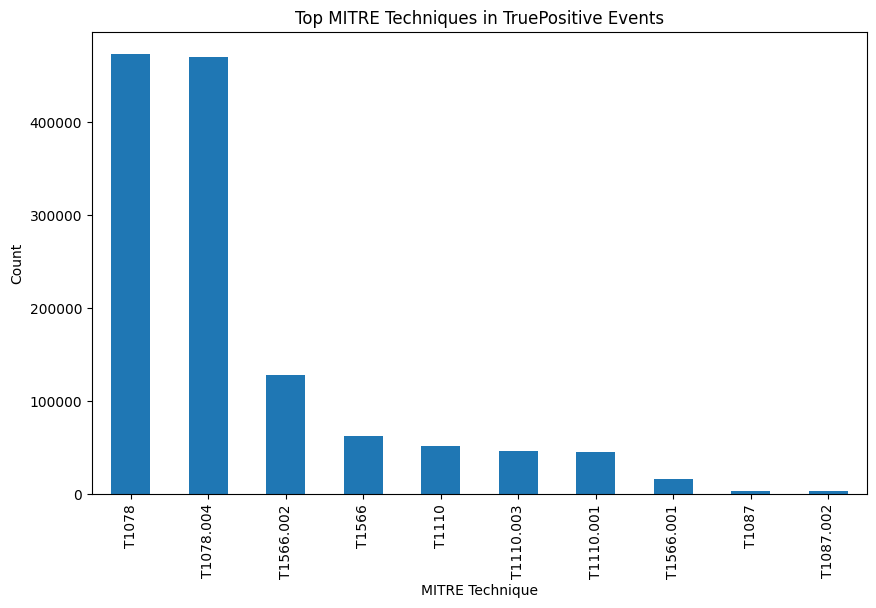

In [20]:
# Step 1: Filter for 'TruePositive' events
true_positive_events = df[df['IncidentGrade'] == 'TruePositive']

# Step 2: Analyze the most common 'Category' in TruePositive events
print("Top categories in TruePositive events:")
category_counts = true_positive_events['Category'].value_counts()
print(category_counts)

# Step 3: Analyze the most frequent 'MitreTechniques' in TruePositive events
print("\nTop MITRE techniques in TruePositive events:")
# Split the semicolon-separated techniques and count individual techniques
technique_counts = true_positive_events['MitreTechniques'].dropna().str.split(';').explode().value_counts()
print(technique_counts)

# Step 4: Combine Category and Techniques for Cross-Analysis
print("\nCross-analysis of Category and MitreTechniques:")
category_technique_counts = true_positive_events.groupby('Category')['MitreTechniques'].count()
print(category_technique_counts)

# Step 5: Visualize the results (optional)
import matplotlib.pyplot as plt

# Bar plot for Categories
plt.figure(figsize=(10, 6))
category_counts.head(10).plot(kind='bar')
plt.title('Top Categories in TruePositive Events')
plt.ylabel('Count')
plt.xlabel('Category')
plt.show()

# Bar plot for MITRE Techniques
plt.figure(figsize=(10, 6))
technique_counts.head(10).plot(kind='bar')
plt.title('Top MITRE Techniques in TruePositive Events')
plt.ylabel('Count')
plt.xlabel('MITRE Technique')
plt.show()


In [21]:
df = df.fillna("Unknown")  # Replace missing values with "Unknown" for categorical features


In [22]:
from sklearn.preprocessing import LabelEncoder

# Example: Label Encoding for 'IncidentGrade'
le = LabelEncoder()
df['IncidentGrade'] = le.fit_transform(df['IncidentGrade'])

# Example: One-Hot Encoding for 'Category'
df = pd.get_dummies(df, columns=['Category'], drop_first=True)

# Example: Multi-Hot Encoding for 'MitreTechniques'
techniques = df['MitreTechniques'].str.get_dummies(sep=';')
df = pd.concat([df, techniques], axis=1)
df.drop('MitreTechniques', axis=1, inplace=True)


In [24]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder

# Example DataFrame - Replace with your dataset
df = pd.DataFrame()  # Assuming you already have the dataset loaded

# List of columns to preprocess
categorical_columns = [
    'Category', 'IncidentGrade', 'ActionGrouped', 'ActionGranular', 'EntityType',
    'EvidenceRole', 'ThreatFamily', 'ResourceType', 'Roles', 'AntispamDirection',
    'SuspicionLevel', 'LastVerdict', 'Usage'
]

# Step 1: Label Encode columns with few unique values
label_encode_columns = ['IncidentGrade', 'SuspicionLevel', 'LastVerdict', 'Usage']

le = LabelEncoder()
for col in label_encode_columns:
    if col in df.columns:
        df[col] = le.fit_transform(df[col].fillna("Unknown"))  # Replace missing with 'Unknown'

# Step 2: One-Hot Encode columns with moderate unique values
one_hot_encode_columns = [
    'Category', 'ActionGrouped', 'ActionGranular', 'EntityType', 'EvidenceRole',
    'ThreatFamily', 'ResourceType', 'Roles', 'AntispamDirection'
]

df = pd.get_dummies(df, columns=one_hot_encode_columns, drop_first=True)

# Step 3: Multi-Hot Encode `MitreTechniques`
if 'MitreTechniques' in df.columns:
    techniques = df['MitreTechniques'].str.get_dummies(sep=';')
    df = pd.concat([df, techniques], axis=1)
    df.drop('MitreTechniques', axis=1, inplace=True)

# Step 4: Handle missing values (for simplicity, filling all NaNs with 0 or "Unknown")
df.fillna(0, inplace=True)

# Display the updated dataset
print("Preprocessed DataFrame:")
print(df.head())


KeyError: "None of [Index(['Category', 'ActionGrouped', 'ActionGranular', 'EntityType',\n       'EvidenceRole', 'ThreatFamily', 'ResourceType', 'Roles',\n       'AntispamDirection'],\n      dtype='object')] are in the [columns]"